In [10]:
%pip install -U qiskit qiskit-ibm-runtime qiskit[visualization] matplotlib

Note: you may need to restart the kernel to use updated packages.


In [2]:

from getpass import getpass
from qiskit_ibm_runtime import QiskitRuntimeService

api_key = getpass("Enter your IBM Quantum API key: ")
crn = input("Paste your IBM Quantum instance CRN: ").strip()

service = QiskitRuntimeService(
    channel="ibm_quantum_platform",
    token=api_key,
    instance=crn
)

print("Successfully connected to IBM Quantum!")


Enter your IBM Quantum API key:  ········
Paste your IBM Quantum instance CRN:  crn:v1:bluemix:public:quantum-computing:us-east:a/0222f50d31f44d74b2f0e9701c6f8bc2:d462f301-569a-42e8-b7b5-dbd297c94eae::


qiskit_runtime_service._discover_account:WARNING:2026-10-10 12:29:23,639: Loading account with the given token. A saved account will not be used.


Successfully connected to IBM Quantum!


In [3]:

backends = service.backends(
    simulator=False,
    operational=True
)

print("Available quantum computers:")
for backend in backends:
    print(backend.name)


Available quantum computers:
ibm_fez
ibm_kingston
ibm_marrakesh


In [4]:

backend = service.least_busy(
    operational=True,
    simulator=False
)

print("Selected backend:", backend.name)


Selected backend: ibm_fez


Circuit A: One X gate


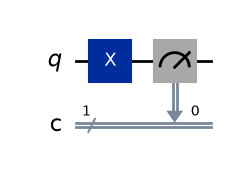

Circuit B: Two X gates


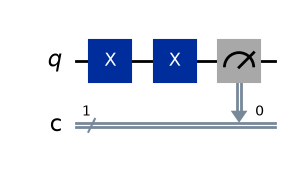

Circuit C: One H gate


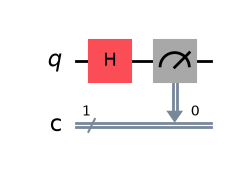

In [5]:

from qiskit import QuantumCircuit

# Circuit A: One X gate
circuit_A = QuantumCircuit(1, 1)
circuit_A.x(0)
circuit_A.measure(0, 0)

# Circuit B: Two X gates
circuit_B = QuantumCircuit(1, 1)
circuit_B.x(0)
circuit_B.x(0)
circuit_B.measure(0, 0)

# Circuit C: One Hadamard gate
circuit_C = QuantumCircuit(1, 1)
circuit_C.h(0)
circuit_C.measure(0, 0)

print("Circuit A: One X gate")
display(circuit_A.draw("mpl"))

print("Circuit B: Two X gates")
display(circuit_B.draw("mpl"))

print("Circuit C: One H gate")
display(circuit_C.draw("mpl"))


In [6]:

from qiskit import transpile
from qiskit_ibm_runtime import SamplerV2

# Prepare circuits for the selected hardware
circuits = [circuit_A, circuit_B, circuit_C]

isa_circuits = transpile(
    circuits,
    backend=backend,
    optimization_level=1
)

# Run on real IBM quantum hardware
sampler = SamplerV2(mode=backend)

job = sampler.run(isa_circuits, shots=100)

print("Job submitted successfully!")
print("Job ID:", job.job_id())

# Wait for the job to finish and retrieve results
results = job.result()

counts_A = results[0].data.c.get_counts()
counts_B = results[1].data.c.get_counts()
counts_C = results[2].data.c.get_counts()

print("\nCircuit A:", counts_A)
print("Circuit B:", counts_B)
print("Circuit C:", counts_C)


C:\Users\aksha\AppData\Local\Temp\ipykernel_42272\715479929.py:14: DeprecationWarning: The SamplerV2 class is deprecated as of qiskit-ibm-runtime 0.50.0 and will be removed no sooner than 3 months after the release date. `qiskit_ibm_runtime.executor_sampler.Sampler` provides a new Sampler implementation that runs all the pre- and post-processing in the client side. The top-level `qiskit_ibm_runtime.Sampler` import will be updated to point to the client-side sampler in an upcoming release, with the legacy Sampler being available until the deprecation is completed.
  sampler = SamplerV2(mode=backend)


Job submitted successfully!
Job ID: db4u4vklf4us73c39hng

Circuit A: {'1': 95, '0': 5}
Circuit B: {'0': 100}
Circuit C: {'0': 59, '1': 41}


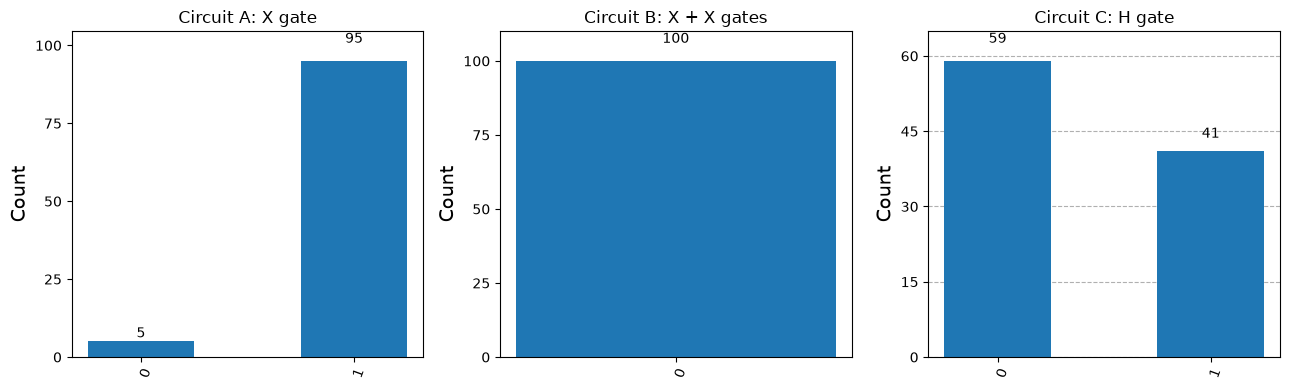

In [7]:

import matplotlib.pyplot as plt
from qiskit.visualization import plot_histogram

fig, axes = plt.subplots(1, 3, figsize=(13, 4))

plot_histogram(counts_A, ax=axes[0])
axes[0].set_title("Circuit A: X gate")

plot_histogram(counts_B, ax=axes[1])
axes[1].set_title("Circuit B: X + X gates")

plot_histogram(counts_C, ax=axes[2])
axes[2].set_title("Circuit C: H gate")

plt.tight_layout()
plt.show()


In [8]:

import pandas as pd

comparison = pd.DataFrame({
    "Circuit": ["A", "B", "C"],
    "Gate": ["X", "X + X", "H"],
    "Prediction": [
        "Outcome 1",
        "Outcome 0",
        "Approximately 50% 0 and 50% 1"
    ],
    "Actual counts": [
        str(counts_A),
        str(counts_B),
        str(counts_C)
    ]
})

display(comparison)


,Circuit,Gate,Prediction,Actual counts
0,A,X,Outcome 1,"{'1': 95, '0': 5}"
1,B,X + X,Outcome 0,{'0': 100}
2,C,H,Approximately 50% 0 and 50% 1,"{'0': 59, '1': 41}"
